In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

paths = [Path("../data/airbnb_london.csv"), Path("data/airbnb_london.csv"),
         Path("airbnb_london.csv"), Path("listings-28.csv")]
data_path = next((p for p in paths if p.exists()), None)
if data_path is None:
    raise FileNotFoundError("London listings CSV not found.")
df = pd.read_csv(data_path, low_memory=False)

def numeric(series):
    return pd.to_numeric(series.astype(str).str.replace(r"[$£€,]", "", regex=True).str.strip(), errors="coerce")

data = df.copy()
for column in ["price", "minimum_nights", "availability_365", "number_of_reviews", "reviews_per_month"]:
    data[column] = numeric(data[column])
data = data[(data.price > 0) & data.room_type.notna()]
data = data[data.price <= data.price.quantile(0.95)].copy()


room_type,listings,median_price,median_total_reviews,median_minimum_nights,median_availability
Entire home/apt,37724,217.00,8.0,2.0,248.0
Hotel room,121,148.00,1.0,1.0,348.0
Private room,18901,80.00,10.0,1.0,259.0
Shared room,163,35.42,16.0,1.0,328.0


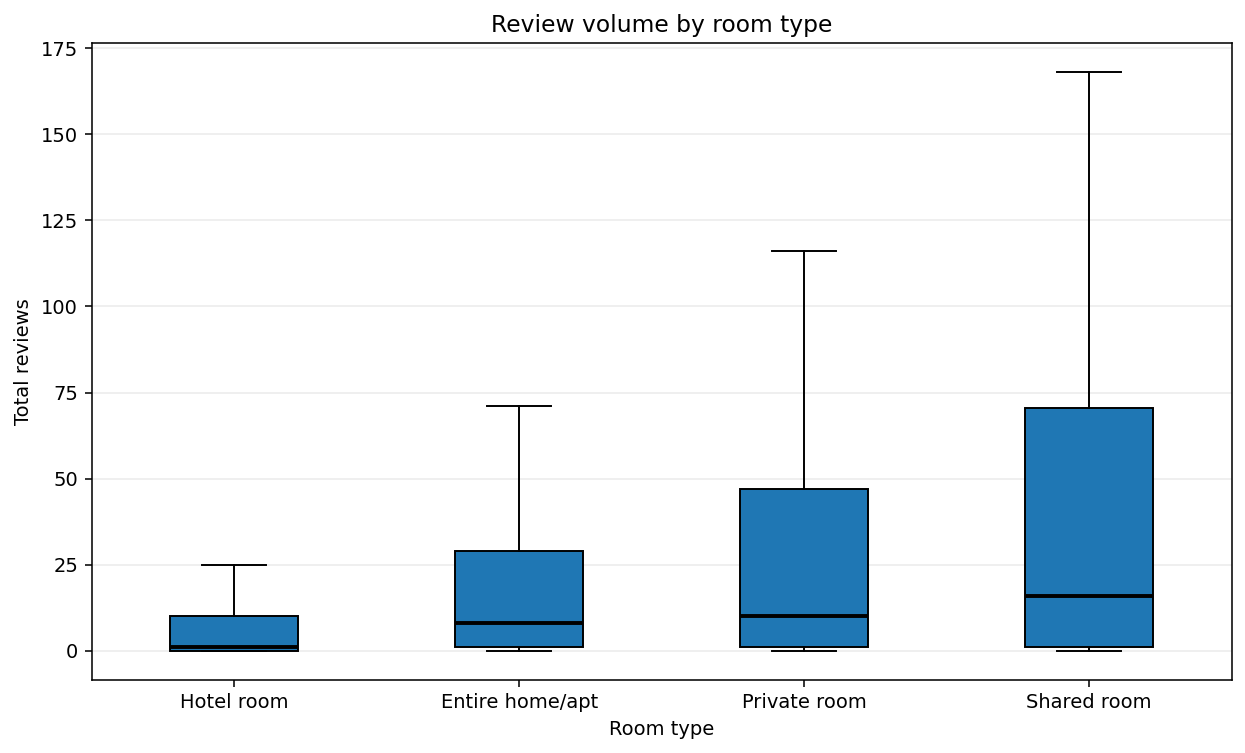

In [2]:
room_summary = data.groupby("room_type").agg(
    listings=("id", "count"), median_price=("price", "median"),
    median_total_reviews=("number_of_reviews", "median"),
    median_minimum_nights=("minimum_nights", "median"),
    median_availability=("availability_365", "median")
).round(2).reset_index()
display(room_summary)

review_data = data.dropna(subset=["number_of_reviews"])
room_order = review_data.groupby("room_type").number_of_reviews.median().sort_values().index.tolist()
fig, ax = plt.subplots(figsize=(9, 5.5))
ax.boxplot([review_data.loc[review_data.room_type == r, "number_of_reviews"] for r in room_order],
           tick_labels=room_order, showfliers=False, patch_artist=True,
           medianprops=dict(color="black", linewidth=2))
ax.set_title("Review volume by room type")
ax.set_xlabel("Room type")
ax.set_ylabel("Total reviews")
ax.grid(axis="y", alpha=0.25)
fig.tight_layout()
plt.show()


room_type,listings,median_minimum_nights,mean_minimum_nights,maximum_minimum_nights
Entire home/apt,37723,2.0,4.03,365.0
Hotel room,121,1.0,1.07,3.0
Private room,18606,1.0,2.96,365.0
Shared room,163,1.0,1.45,30.0


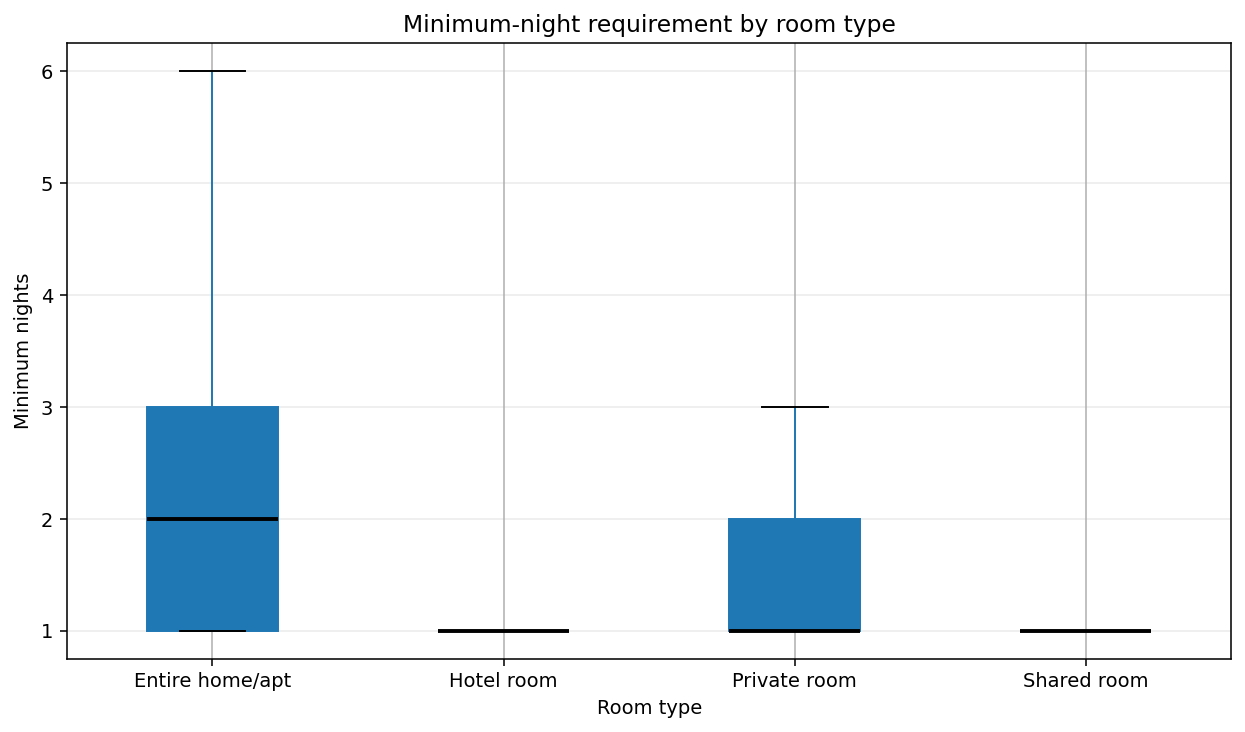

In [3]:
stay_data = data.dropna(subset=["minimum_nights"])
stay_data = stay_data[stay_data.minimum_nights.between(1, 365)]
stay_summary = stay_data.groupby("room_type").agg(
    listings=("id", "count"), median_minimum_nights=("minimum_nights", "median"),
    mean_minimum_nights=("minimum_nights", "mean"),
    maximum_minimum_nights=("minimum_nights", "max")
).round(2).reset_index()
display(stay_summary)

fig, ax = plt.subplots(figsize=(9, 5.5))
stay_data.boxplot(column="minimum_nights", by="room_type", ax=ax, showfliers=False,
                  patch_artist=True, medianprops=dict(color="black", linewidth=2))
ax.set_title("Minimum-night requirement by room type")
fig.suptitle("")
ax.set_xlabel("Room type")
ax.set_ylabel("Minimum nights")
ax.grid(axis="y", alpha=0.25)
fig.tight_layout()
plt.show()


host_id,listings,median_price,median_reviews
446820235,339,359.00,0.0
11515631,135,252.00,63.0
7701687,119,359.70,11.0
131418248,107,55.00,2.0
527114813,102,179.00,20.5
124359784,101,162.20,25.0
185324181,101,150.00,11.0
92967793,95,77.00,103.0
89355192,93,200.72,25.0
509948385,92,118.00,3.0


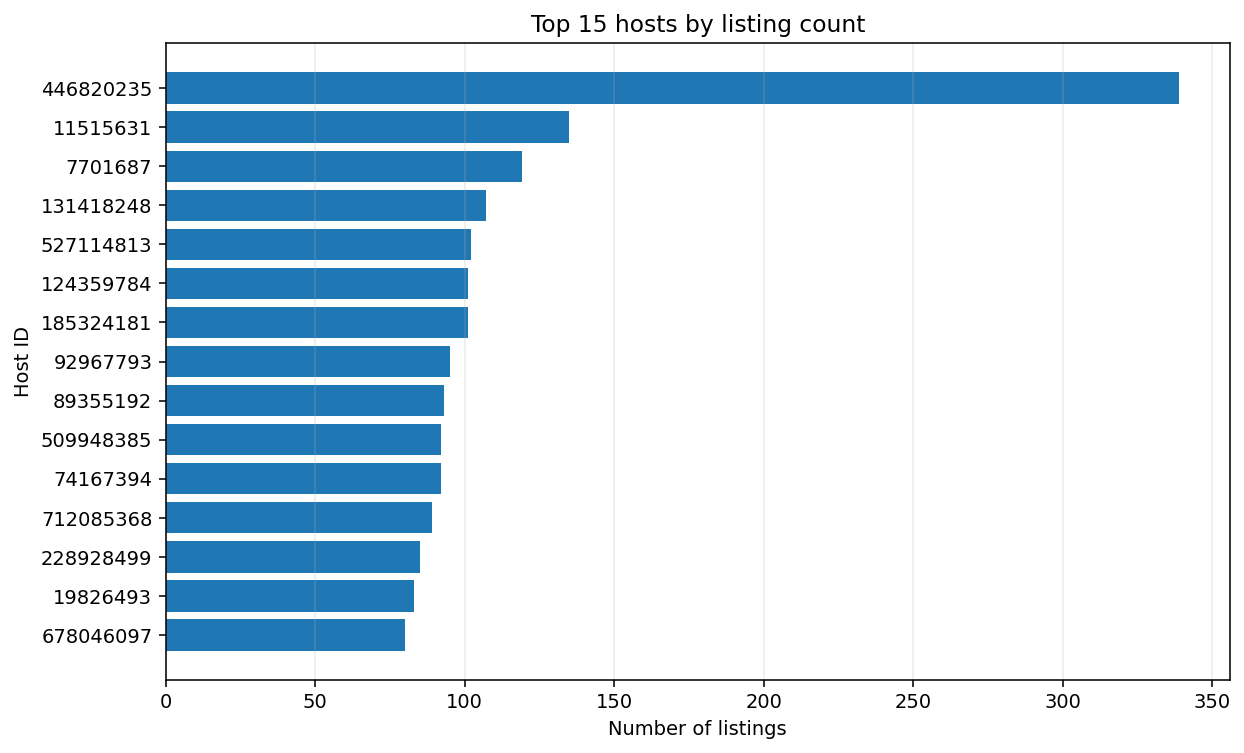

In [4]:
host_summary = data.groupby("host_id").agg(
    listings=("id", "count"), median_price=("price", "median"),
    median_reviews=("number_of_reviews", "median")
).sort_values("listings", ascending=False).head(15).reset_index()
display(host_summary.round(2))

fig, ax = plt.subplots(figsize=(9, 5.5))
ax.barh(host_summary.host_id.astype(str), host_summary.listings)
ax.invert_yaxis()
ax.set_title("Top 15 hosts by listing count")
ax.set_xlabel("Number of listings")
ax.set_ylabel("Host ID")
ax.grid(axis="x", alpha=0.25)
fig.tight_layout()
plt.show()
